In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [13]:
# Load the Uber dataset
df = pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [14]:
# Pre-processing
df = df.drop(['Unnamed: 0', 'key'], axis=1)
df = df.dropna()

In [15]:
from math import radians, sin, cos, sqrt, atan2

def calculate_distance(row):
    lat1 = radians(row['pickup_latitude'])
    lon1 = radians(row['pickup_longitude'])
    lat2 = radians(row['dropoff_latitude'])
    lon2 = radians(row['dropoff_longitude'])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
    c = 2 * atan2(sqrt(a), sqrt(1-a))

    return 6371 * c

df['distance'] = df.apply(calculate_distance, axis=1)



In [16]:
# Remove invalid values
df = df[(df['fare_amount'] > 0) & (df['distance'] > 0)]

# Take 50,000 rows for faster processing
df = df.sample(50000, random_state=42)

In [17]:
Q1 = df[['fare_amount', 'distance']].quantile(0.25)

Q3 = df[['fare_amount', 'distance']].quantile(0.75)

IQR = Q3 - Q1

df = df[
    ~((df[['fare_amount', 'distance']] < Q1 - 1.5 * IQR) |
      (df[['fare_amount', 'distance']] > Q3 + 1.5 * IQR)).any(axis=1)
]

Correlation Matrix:
                 fare_amount  distance  passenger_count
fare_amount         1.000000  0.817494         0.013637
distance            0.817494  1.000000         0.001151
passenger_count     0.013637  0.001151         1.000000


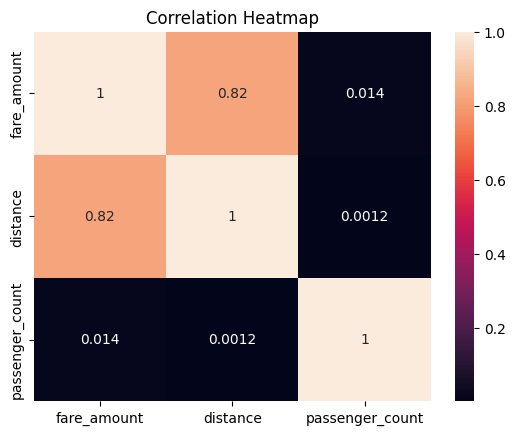

In [18]:
# Correlation
print("Correlation Matrix:")

print(df[['fare_amount', 'distance', 'passenger_count']].corr())

sns.heatmap(
    df[['fare_amount', 'distance', 'passenger_count']].corr(),
    annot=True
)

plt.title("Correlation Heatmap")
plt.show()

In [19]:
# Features and target
X = df[['distance', 'passenger_count']]

y = df['fare_amount']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [20]:
print("Training Linear Regression...")

lr = LinearRegression()

lr.fit(X_train, y_train)

pred_lr = lr.predict(X_test)

Training Linear Regression...


In [21]:
print("Training Random Forest...")

rf = RandomForestRegressor(
    n_estimators=20,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)

Training Random Forest...


In [22]:
# Evaluation
results = pd.DataFrame({

    'Model': ['Linear Regression', 'Random Forest'],

    'R2 Score': [
        r2_score(y_test, pred_lr),
        r2_score(y_test, pred_rf)
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_test, pred_lr)),
        np.sqrt(mean_squared_error(y_test, pred_rf))
    ],

    'MAE': [
        mean_absolute_error(y_test, pred_lr),
        mean_absolute_error(y_test, pred_rf)
    ]
})

print("\n===== MODEL COMPARISON =====")

print(results.to_string(index=False))


===== MODEL COMPARISON =====
            Model  R2 Score     RMSE      MAE
Linear Regression  0.659875 2.303301 1.645210
    Random Forest  0.546838 2.658634 1.910917


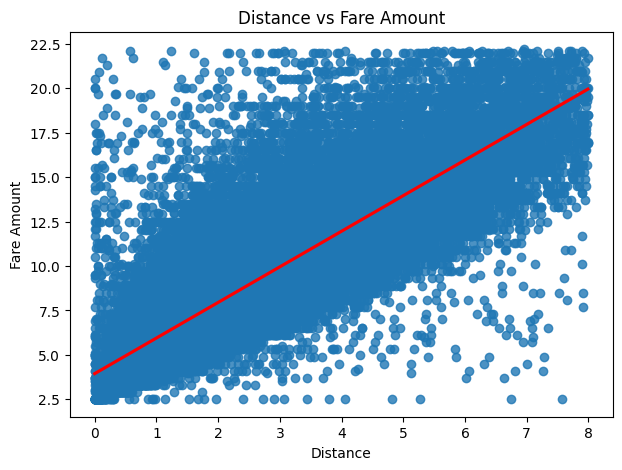

In [23]:
plt.figure(figsize=(7,5))

sns.regplot(
    x=df['distance'],
    y=df['fare_amount'],
    line_kws={'color': 'red'}
)

plt.title("Distance vs Fare Amount")
plt.xlabel("Distance")
plt.ylabel("Fare Amount")

plt.show()

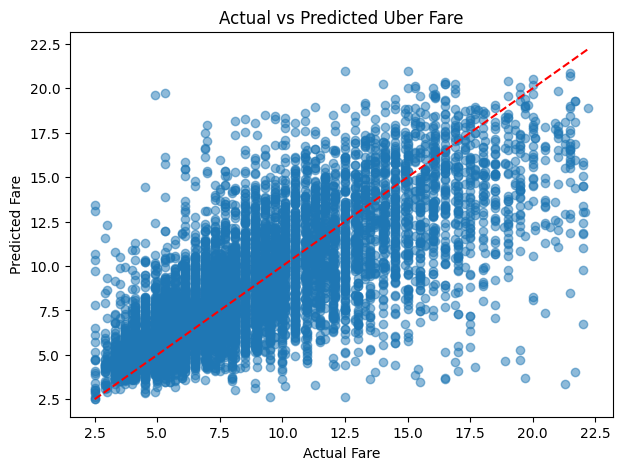

In [24]:
plt.figure(figsize=(7,5))

plt.scatter(y_test, pred_rf, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")

plt.title("Actual vs Predicted Uber Fare")

plt.show()